<a href="https://colab.research.google.com/github/famub/2026-GP1-02/blob/main/mufsal_pre2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("shashwatwork/knee-osteoarthritis-dataset-with-severity")
print("Path to dataset files:", path)

100%|██████████| 204M/204M [00:01<00:00, 165MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/shashwatwork/knee-osteoarthritis-dataset-with-severity/versions/1


In [2]:
!ls {path}

auto_test  test  train	val


In [3]:
from torchvision import transforms, datasets

base = path

tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

print("train:", len(train), "| val:", len(val), "| test:", len(test))
print("classes:", train.classes)


train: 5778 | val: 826 | test: 1656
classes: ['0', '1', '2', '3', '4']


In [4]:
from collections import Counter

for name, ds in [("train", train), ("val", val), ("test", test)]:
    counts = Counter(ds.targets)
    print(name, {ds.classes[k]: v for k, v in sorted(counts.items())})


train {'0': 2286, '1': 1046, '2': 1516, '3': 757, '4': 173}
val {'0': 328, '1': 153, '2': 212, '3': 106, '4': 27}
test {'0': 639, '1': 296, '2': 447, '3': 223, '4': 51}


In [5]:
import torch

counts = Counter(train.targets)
total = sum(counts.values())
weights = [total / (5 * counts[i]) for i in range(5)]
class_weights = torch.tensor(weights, dtype=torch.float)

print("class weights:", [round(w, 2) for w in weights])


class weights: [0.51, 1.1, 0.76, 1.53, 6.68]


In [6]:
train_tf = transforms.Compose([
    transforms.Grayscale(3),
    transforms.Resize((224,224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
print("train:", len(train))


train: 5778


In [7]:
from torch.utils.data import DataLoader

val = datasets.ImageFolder(f"{base}/val", transform=tf)
test = datasets.ImageFolder(f"{base}/test", transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader = DataLoader(val, batch_size=32, shuffle=False)
test_loader = DataLoader(test, batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("labels:", labels[:10])


batch shape: torch.Size([32, 3, 224, 224])
labels: tensor([2, 0, 0, 0, 0, 0, 0, 2, 0, 3])


In [8]:
import cv2
import numpy as np
from PIL import Image
from torch.utils.data import DataLoader

# 1) دالة التنظيف: noise reduction + تحسين التباين
class Denoise:
    def __call__(self, img):
        g = np.array(img.convert("L"))                      # رمادي
        g = cv2.GaussianBlur(g, (3, 3), 0)                  # إزالة الضوضاء
        g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)  # تحسين التباين
        return Image.fromarray(g)

# 2) pipeline للـ val و test (بدون augmentation)
tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 3) pipeline للـ train (مع augmentation)
train_tf = transforms.Compose([
    Denoise(),
    transforms.Grayscale(3),
    transforms.Resize((224, 224)),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

# 4) نعيد تحميل الداتا بالـ pipeline الجديد
train = datasets.ImageFolder(f"{base}/train", transform=train_tf)
val   = datasets.ImageFolder(f"{base}/val",   transform=tf)
test  = datasets.ImageFolder(f"{base}/test",  transform=tf)

train_loader = DataLoader(train, batch_size=32, shuffle=True)
val_loader   = DataLoader(val,   batch_size=32, shuffle=False)
test_loader  = DataLoader(test,  batch_size=32, shuffle=False)

images, labels = next(iter(train_loader))
print("batch shape:", images.shape)
print("train:", len(train), "| val:", len(val), "| test:", len(test))


batch shape: torch.Size([32, 3, 224, 224])
train: 5778 | val: 826 | test: 1656


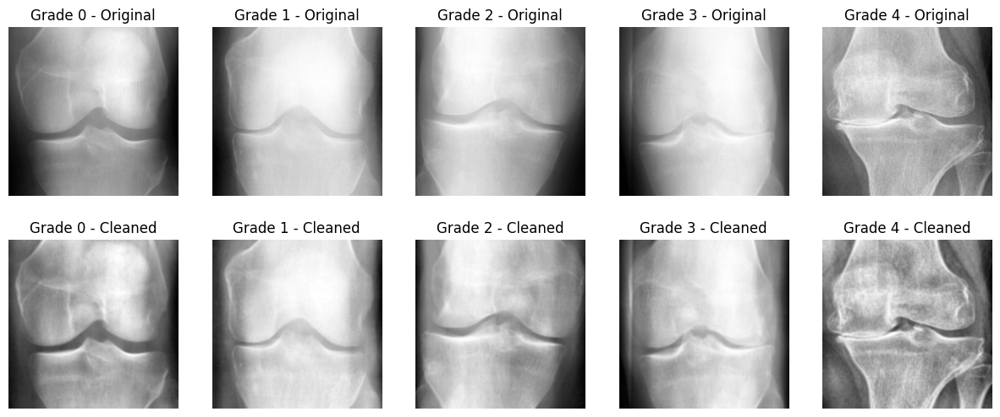

In [9]:
import matplotlib.pyplot as plt
from PIL import Image

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    path_k = train.samples[train.targets.index(k)][0]
    original = Image.open(path_k).convert("L")
    cleaned = Denoise()(original)
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Original"); axes[0][k].axis("off")
    axes[1][k].imshow(cleaned, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cleaned"); axes[1][k].axis("off")
plt.show()

# مو مهم بس عشان اشوف الصور قبل وبعد

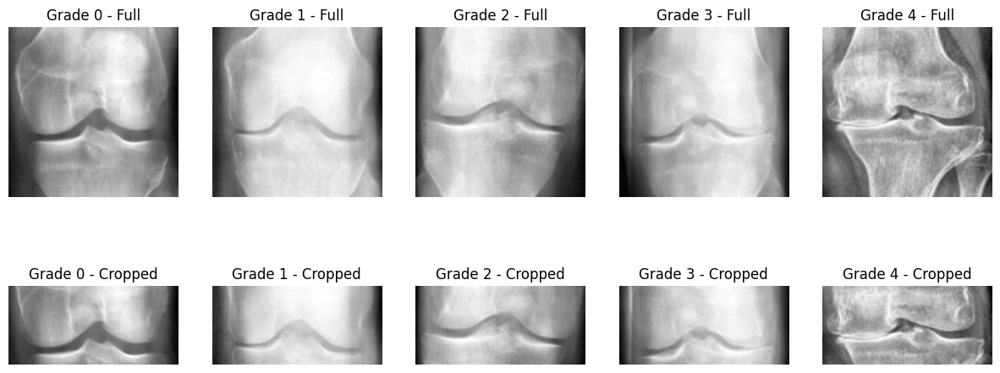

In [10]:
import matplotlib.pyplot as plt
from PIL import Image

def crop_center(img, top=60, bottom=60):
    img = img.resize((224, 224))
    return img.crop((0, top, 224, 224 - bottom))   # 224 x 104

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for k in range(5):
    p = train.samples[train.targets.index(k)][0]
    original = Denoise()(Image.open(p).convert("L")).resize((224, 224))
    cropped = crop_center(Denoise()(Image.open(p).convert("L")))
    axes[0][k].imshow(original, cmap="gray"); axes[0][k].set_title(f"Grade {k} - Full"); axes[0][k].axis("off")
    axes[1][k].imshow(cropped, cmap="gray"); axes[1][k].set_title(f"Grade {k} - Cropped"); axes[1][k].axis("off")
plt.show()


batch shape: torch.Size([32, 3, 104, 224])

Total images: 8260 | joint found: 7939 | fallback crop: 321
Joint far from the usual position (shift was clipped): 173
  Grade 0: joint not found in 58 of 3253 (2%)
  Grade 1: joint not found in 24 of 1495 (2%)
  Grade 2: joint not found in 78 of 2175 (4%)
  Grade 3: joint not found in 106 of 1086 (10%)
  Grade 4: joint not found in 55 of 251 (22%)
When the joint is found, the crop always covers rows 88 to 160


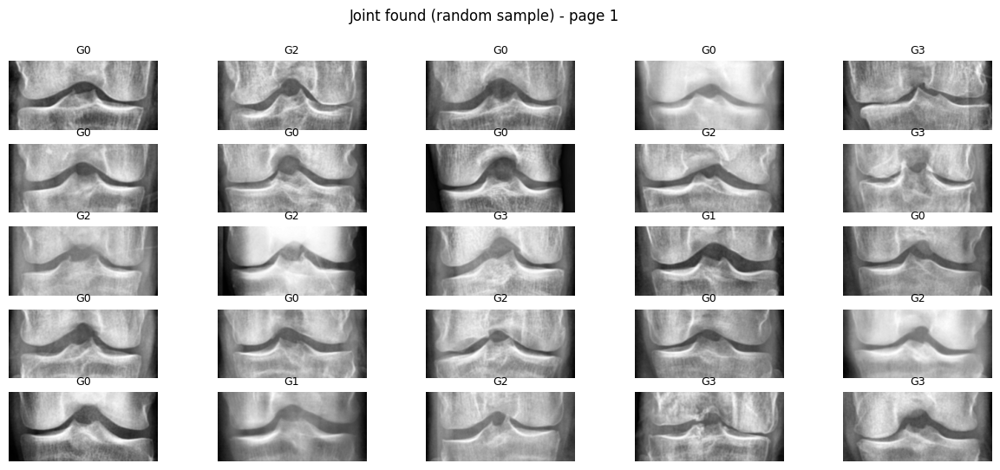

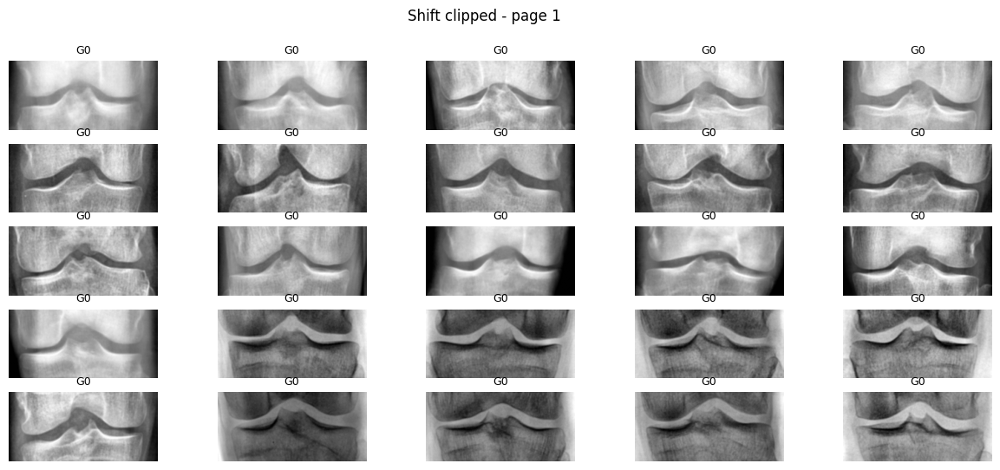

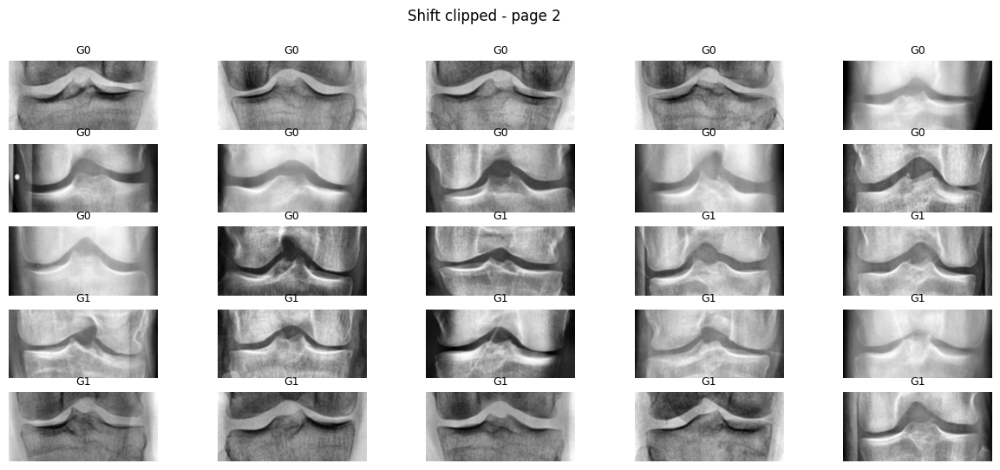

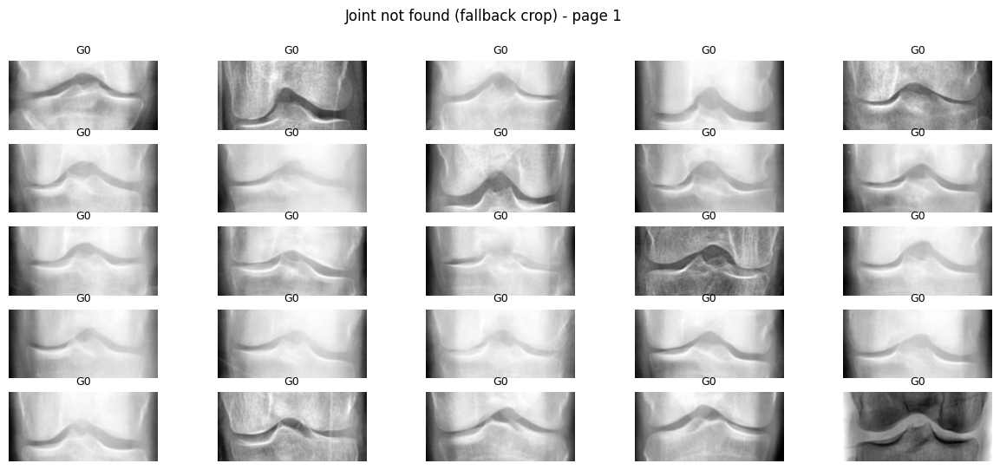

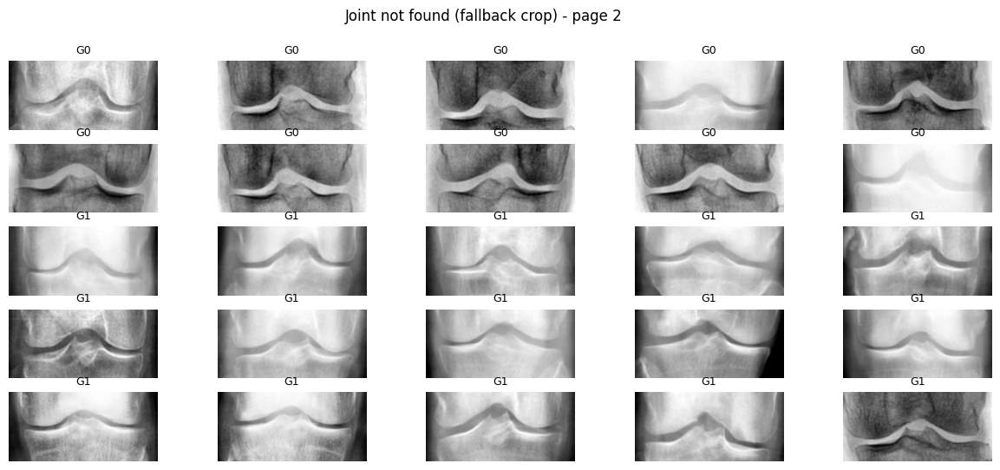

...

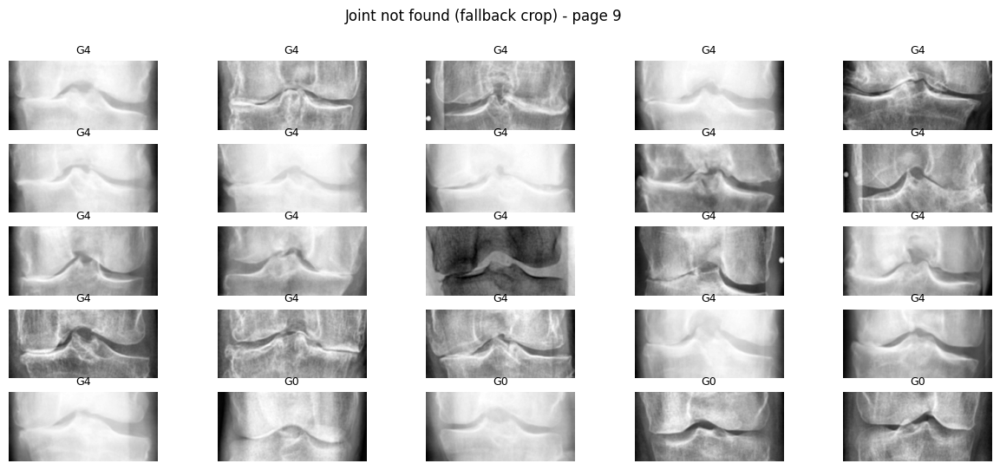

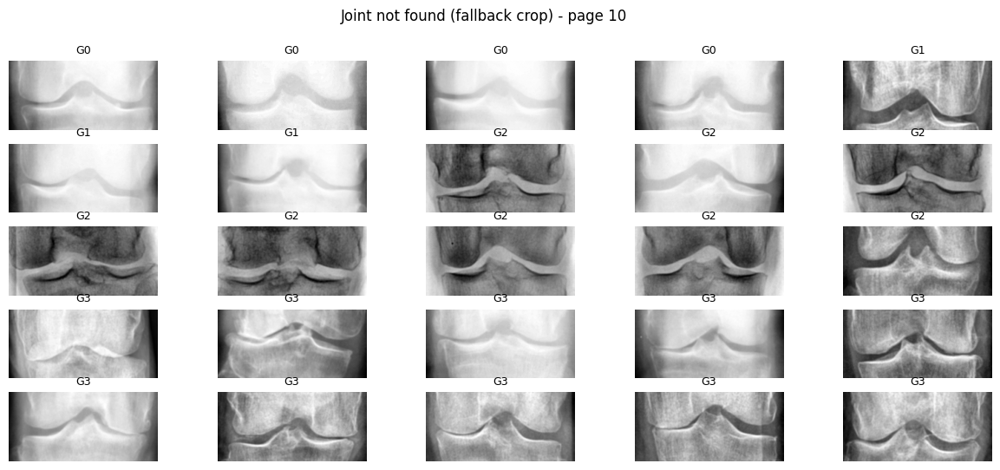

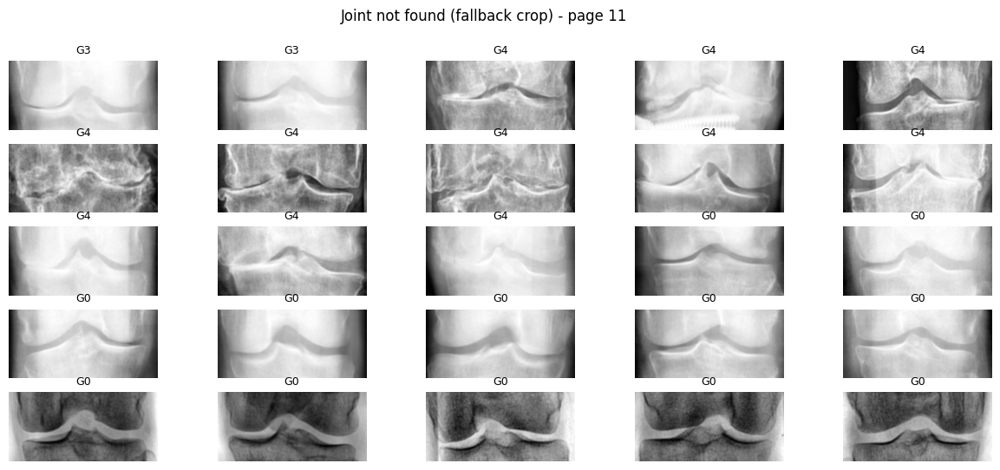

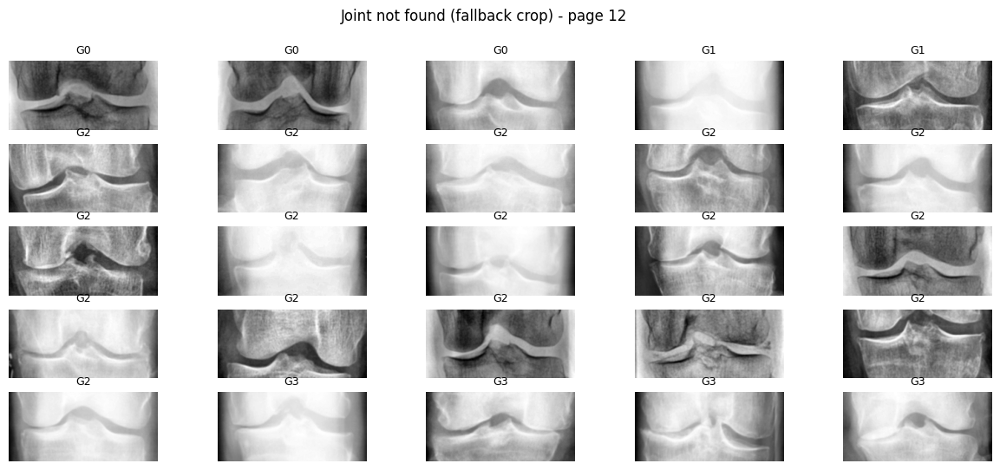

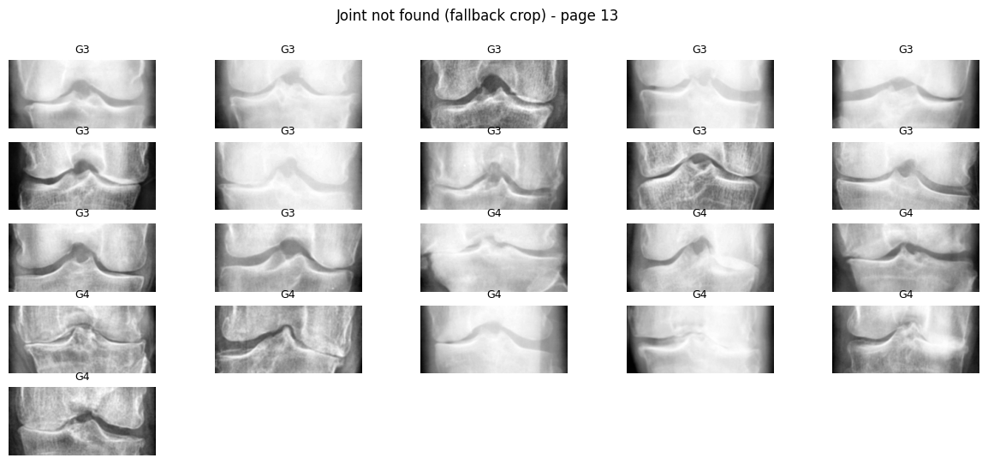

In [11]:
# ======================= NEW: joint-aware crop (single cell) =======================
# Run this AFTER the original cells (it needs `base` and the original `Denoise` class).
# Nothing from the original pipeline is changed: every new object ends with "_smart".
import random
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- Settings (change values here only) ----------
SIZE = 224
WINDOW_H = 104        # crop height (same as the 60/60 crop: 224 - 60 - 60)
PRIOR_ROW = 124       # most likely joint row (measured median 0.554 x 224)
MAX_SHIFT = 16        # max shift allowed from PRIOR_ROW (protects against a wrong detection)
FALLBACK_ROW = 124    # crop center when no joint is found (use 112 for the exact 60/60 crop)
RUN_CHECK = True      # True = scan all images and show examples, False = skip the check


# ---------- 1) Find the joint space ----------
def find_joint_row(gray, lo=0.40, hi=0.70, min_prom=4):
    """Return the row of the joint space, or None if it is not found."""
    H, W = gray.shape
    cols = gray[:, int(W * 0.25):int(W * 0.75)].astype(np.float32)   # central columns only
    prof = gaussian_filter1d(cols.mean(axis=1), sigma=H * 0.02)      # smoothed brightness of each row
    a, b = int(H * lo), int(H * hi)                                  # search only where the joint usually is
    peaks, props = find_peaks(-prof[a:b], prominence=min_prom)       # darkest valley = joint gap
    if len(peaks) == 0:
        return None
    return a + int(peaks[np.argmax(props["prominences"])])


# ---------- 2) Denoise + crop around the joint ----------
class SmartCrop:
    def __init__(self):
        self.denoise = Denoise()                                     # the original Denoise class (unchanged)
    def __call__(self, img):
        img = img.convert("L").resize((SIZE, SIZE))
        row = find_joint_row(np.array(img))                          # detect on the raw image
        if row is None:
            center = FALLBACK_ROW                                    # not found: crop around the most likely position
        else:                                                        # found: center on it, with a limited shift
            center = int(np.clip(row, PRIOR_ROW - MAX_SHIFT, PRIOR_ROW + MAX_SHIFT))
        top = center - WINDOW_H // 2
        return self.denoise(img).crop((0, top, SIZE, top + WINDOW_H))   # 224 x 104


# ---------- 3) Same pipeline as the original, but SmartCrop replaces Denoise + Resize ----------
# No Resize here: SmartCrop already returns the final 224 x 104 image.
tf_smart = transforms.Compose([                                      # val / test (no augmentation)
    SmartCrop(),
    transforms.Grayscale(3),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])
train_tf_smart = transforms.Compose([                                # train (with augmentation)
    SmartCrop(),
    transforms.Grayscale(3),
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
])

train_smart = datasets.ImageFolder(f"{base}/train", transform=train_tf_smart)
val_smart   = datasets.ImageFolder(f"{base}/val",   transform=tf_smart)
test_smart  = datasets.ImageFolder(f"{base}/test",  transform=tf_smart)

train_loader_smart = DataLoader(train_smart, batch_size=32, shuffle=True,  num_workers=2)
val_loader_smart   = DataLoader(val_smart,   batch_size=32, shuffle=False, num_workers=2)
test_loader_smart  = DataLoader(test_smart,  batch_size=32, shuffle=False, num_workers=2)
print("batch shape:", next(iter(train_loader_smart))[0].shape)       # expected [32, 3, 104, 224]


# ---------- 4) Check (a bit slow; set RUN_CHECK = False once you are done) ----------
if RUN_CHECK:
    info = []                                        # (grade, joint row or None, image path)
    for ds in (train_smart, val_smart, test_smart):
        for p, g in ds.samples:
            gray = np.array(Image.open(p).convert("L").resize((SIZE, SIZE)))
            info.append((g, find_joint_row(gray), p))
    found = [x for x in info if x[1] is not None]
    fallback = [x for x in info if x[1] is None]
    clipped = [x for x in found if abs(x[1] - PRIOR_ROW) > MAX_SHIFT]

    print(f"\nTotal images: {len(info)} | joint found: {len(found)} | fallback crop: {len(fallback)}")
    print(f"Joint far from the usual position (shift was clipped): {len(clipped)}")
    for k in range(5):
        n = sum(1 for x in info if x[0] == k)
        f = sum(1 for x in fallback if x[0] == k)
        print(f"  Grade {k}: joint not found in {f} of {n} ({100 * f / n:.0f}%)")
    lo_c = PRIOR_ROW + MAX_SHIFT - WINDOW_H // 2
    hi_c = PRIOR_ROW - MAX_SHIFT + WINDOW_H // 2
    print(f"When the joint is found, the crop always covers rows {lo_c} to {hi_c}")

    sc = SmartCrop()
    def show_pages(items, title, max_pages=20):
        for pg in range(min(max_pages, -(-len(items) // 25))):
            fig, axes = plt.subplots(5, 5, figsize=(15, 6))
            for ax in axes.ravel(): ax.axis("off")
            for ax, x in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
                ax.imshow(sc(Image.open(x[2])), cmap="gray")         # same image the model sees
                ax.set_title(f"G{x[0]}", fontsize=9)
            fig.suptitle(f"{title} - page {pg + 1}")
            plt.show()

    random.seed(1)
    show_pages(random.sample(found, 25), "Joint found (random sample)", 1)
    show_pages(clipped, "Shift clipped", 2)
    show_pages(fallback, "Joint not found (fallback crop)")


train | ok 5760 | off_center 12 | edge 4 | fallback 2
val   | ok 819 | off_center 4 | edge 3 | fallback 0
test  | ok 1652 | off_center 2 | edge 2 | fallback 0


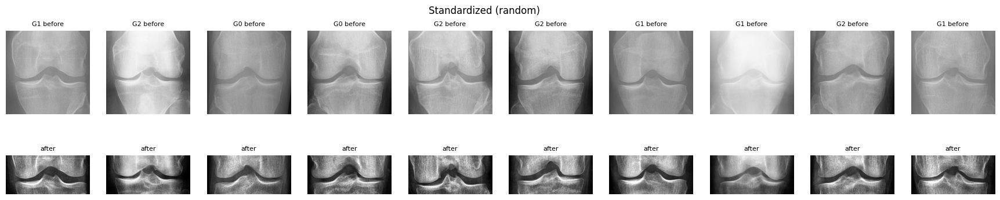

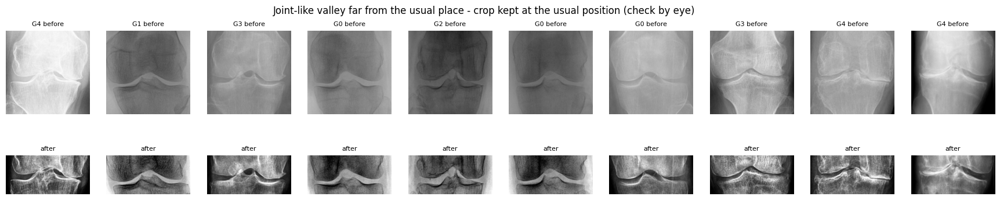

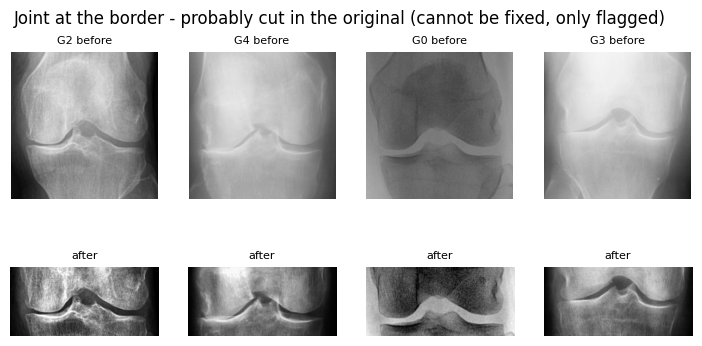

Mean-brightness std over 300 images: before 28.8 -> after 0.1


In [12]:
# ============ NEW (separate cell, run after the original cells) ============
# Image standardization: same brightness/contrast + joint centered + flag images with a cut joint.
# Nothing existing is changed. All new names end with "_std".
import cv2, numpy as np
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks
import matplotlib.pyplot as plt

# ---------- Settings ----------
SIZE_STD = 224
WINDOW_H_STD = 104         # output = 224 x 104
TARGET_MEAN = 110.0        # every image gets this mean brightness (via a gamma curve, no clipping)

MIN_CONTRAST = 4                        # weak valley = joint not clear (usual band)
WIDE_PROM = 10                          # stricter depth needed when the joint is far from its usual place


def joint_row_std(gray, lo=0.40, hi=0.70, min_prom=MIN_CONTRAST):
    """Row of the joint gap (darkest valley in the central columns) or None."""
    H, W = gray.shape
    cols = gray[:, int(W * .25):int(W * .75)].astype(np.float32)
    cols = np.minimum(cols, np.percentile(cols, 95))        # metal implants / very bright parts must not decide
    prof = gaussian_filter1d(np.median(cols, axis=1), sigma=H * 0.02)   # median = robust to a plate on one side
    a, b = int(H * lo), int(H * hi)
    pk, pr = find_peaks(-prof[a:b], prominence=min_prom)
    return None if len(pk) == 0 else a + int(pk[np.argmax(pr["prominences"])])


def normalize_std(g):
    """Uniform brightness / contrast WITHOUT cutting off pixels.
    1) stretch the 0.5-99.5 percentile range to 5-250 (only ~1% of the pixels are touched)
    2) CLAHE (local contrast, same settings as the original pipeline)
    3) gamma curve chosen per image so the mean brightness = TARGET_MEAN
       (a gamma curve moves the mid-tones only: black stays black, white stays white, nothing is clipped)."""
    lo, hi = np.percentile(g, (0.5, 99.5))
    f = np.clip((g.astype(np.float32) - lo) / max(hi - lo, 1), 0, 1)
    g = (5 + f * 245).astype(np.uint8)
    g = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(g)
    return match_mean_std(g)


def match_mean_std(g):
    """Gamma curve so that the mean brightness = TARGET_MEAN (black stays black, white stays white)."""
    x = g.astype(np.float32) / 255
    a, b = np.log(0.2), np.log(5.0)                         # search the gamma in log-space (bisection)
    for _ in range(25):
        m = (a + b) / 2
        if (x ** np.exp(m)).mean() * 255 > TARGET_MEAN:     # still too bright -> larger gamma (darker)
            a = m
        else:
            b = m
    return np.round(x ** np.exp((a + b) / 2) * 255).astype(np.uint8)


def standardize_std(img):
    """PIL image -> (standardized PIL image 224x104, status).
    status: ok         joint found in its usual place (shift limited to +/-16 px)
            off_center a valley far from the usual place -> NOT trusted: crop stays at the usual position (flagged for review)
            edge       a clear valley only very near the top/bottom border -> joint probably cut in the original
            fallback   no joint found -> crop around the most likely position"""
    g = np.array(img.convert("L").resize((SIZE_STD, SIZE_STD)))

    g = normalize_std(g)

    # 2) joint-centered crop (detect on the standardized image)
    status = "ok"
    row = joint_row_std(g)                                          # tier 1: usual band (40-70% of the height)
    if row is not None:
        row = int(np.clip(row, 124 - 16, 124 + 16))                 # small shift only: protects against wrong detections
    else:
        far = joint_row_std(g, lo=0.25, hi=0.75, min_prom=WIDE_PROM)   # tier 2: wider band, needs a clearer valley
        if far is not None:
            row, status = 124, "off_center"                         # do NOT follow it: a far valley is more often bone shadow than the joint
        elif joint_row_std(g, lo=0.08, hi=0.92, min_prom=WIDE_PROM) is not None:
            row, status = 124, "edge"                               # tier 3: joint at the border -> probably cut
        else:
            row, status = 124, "fallback"
    row = int(np.clip(row, WINDOW_H_STD // 2, SIZE_STD - WINDOW_H_STD // 2))   # the window must stay inside the image
    top = row - WINDOW_H_STD // 2
    crop = g[top:top + WINDOW_H_STD]
    return Image.fromarray(match_mean_std(crop)), status        # brightness is fixed on the crop = what the model sees


# ---------- Scan all images, count the problems, show examples ----------
def scan_std(ds, name):
    out = {"ok": [], "fallback": [], "off_center": [], "edge": []}
    for p, y in ds.samples:
        _, st = standardize_std(Image.open(p))
        out[st].append((p, y))
    print(f"{name:5s} | ok {len(out['ok'])} | off_center {len(out['off_center'])} | edge {len(out['edge'])} | fallback {len(out['fallback'])}")
    return out

SCAN_STD = {n: scan_std(d, n) for n, d in [("train", train), ("val", val), ("test", test)]}

def show_std(items, title, n=10):
    n = max(1, min(n, len(items)))                          # only as many columns as there are images (no empty plots)
    fig, ax = plt.subplots(2, n, figsize=(2.2 * n, 4.2), squeeze=False)
    for i, (p, y) in enumerate(items[:n]):
        im = Image.open(p).convert("L").resize((SIZE_STD, SIZE_STD))
        ax[0][i].imshow(im, cmap="gray", vmin=0, vmax=255); ax[0][i].set_title(f"G{y} before", fontsize=8)
        ax[1][i].imshow(standardize_std(im)[0], cmap="gray", vmin=0, vmax=255); ax[1][i].set_title("after", fontsize=8)
        ax[0][i].axis("off"); ax[1][i].axis("off")
    fig.suptitle(title); plt.show()

import random; random.seed(0)
show_std(random.sample(SCAN_STD["train"]["ok"], 10), "Standardized (random)")
for key, title in [("off_center", "Joint-like valley far from the usual place - crop kept at the usual position (check by eye)"),
                   ("edge", "Joint at the border - probably cut in the original (cannot be fixed, only flagged)")]:
    if SCAN_STD["train"][key]:
        show_std(random.sample(SCAN_STD["train"][key], min(10, len(SCAN_STD["train"][key]))), title)

# Brightness check: spread of mean brightness before vs after (smaller = more uniform)
b_before, b_after = [], []
for p, _ in random.sample(train.samples, 300):
    im = Image.open(p).convert("L").resize((SIZE_STD, SIZE_STD))
    b_before.append(np.array(im).mean()); b_after.append(np.array(standardize_std(im)[0]).mean())
print(f"Mean-brightness std over 300 images: before {np.std(b_before):.1f} -> after {np.std(b_after):.1f}")


  train: 2000/5778
  train: 4000/5778

Images checked: 8260  (train 5778 | val 826 | test 1656)

check                             images      %
[HARD] wrong_size                      0   0.0%
[HARD] brightness_off                  0   0.0%
[HARD] saturated (added)             439   5.3%
[HARD] low_contrast                    0   0.0%
[HARD] joint_near_crop_edge         1911  23.1%
[soft] noisy_original                 14   0.2%
[soft] blurry                        166   2.0%
[soft] big_black_area                  0   0.0%
[soft] joint_not_found                 2   0.0%
[soft] joint_far_from_usual           18   0.2%
[soft] joint_at_border (cut?)          9   0.1%
[soft] joint_weak_in_crop              0   0.0%
clean (no flag at all)              5853  70.9%

Brightness uniformity (std of mean brightness across images; smaller = more uniform):
  before standardization: 27.3   after: 0.1
Contrast (std of pixel values): spread across images before 14.4 | after 5.0
Pure black/white pixels

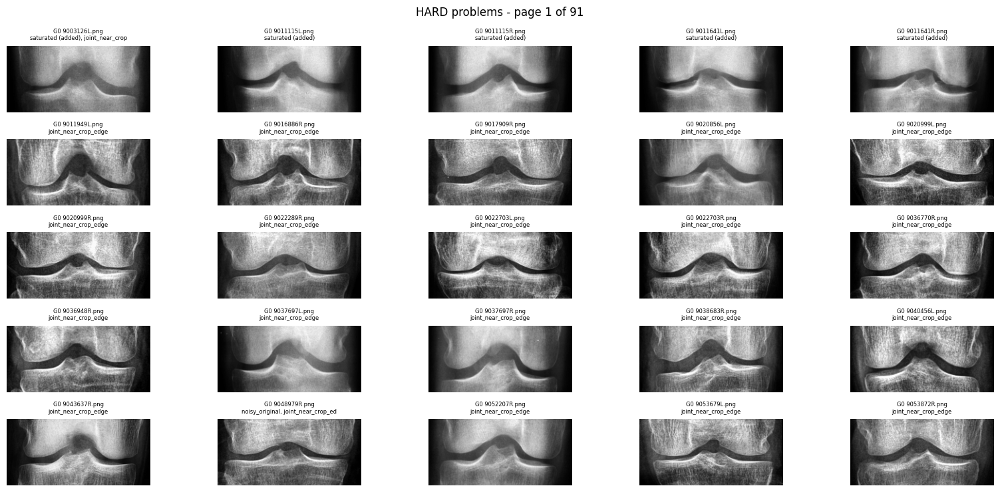

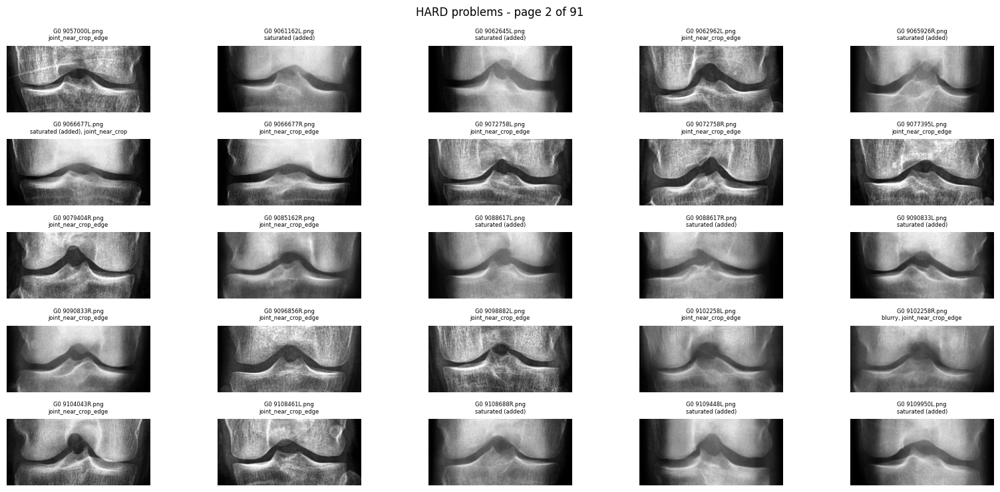

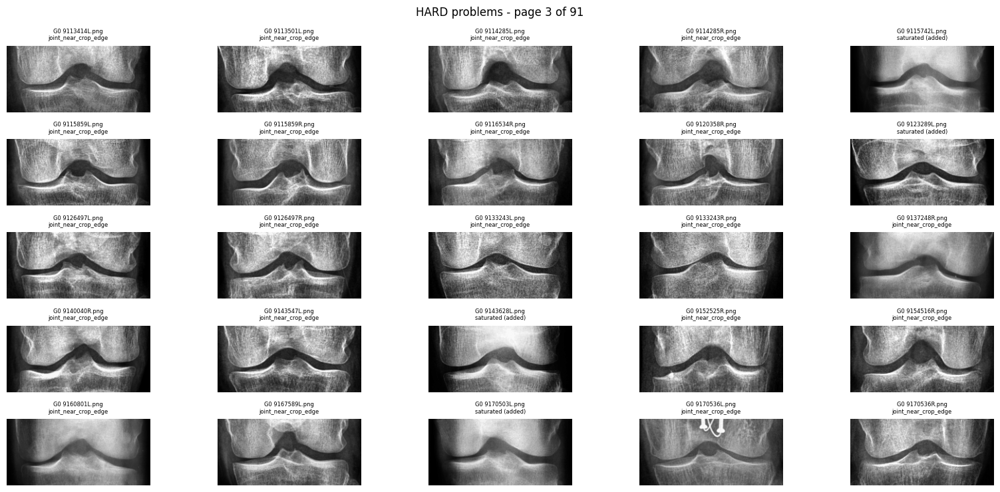

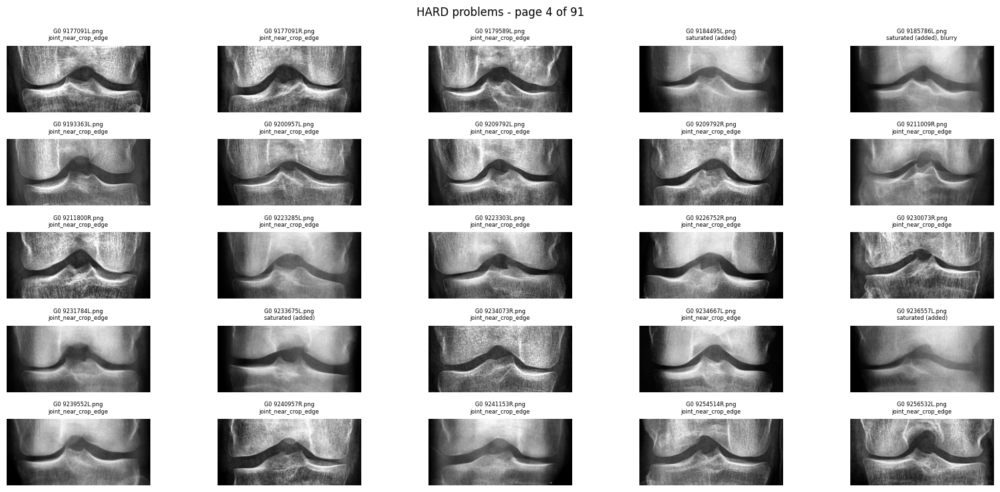

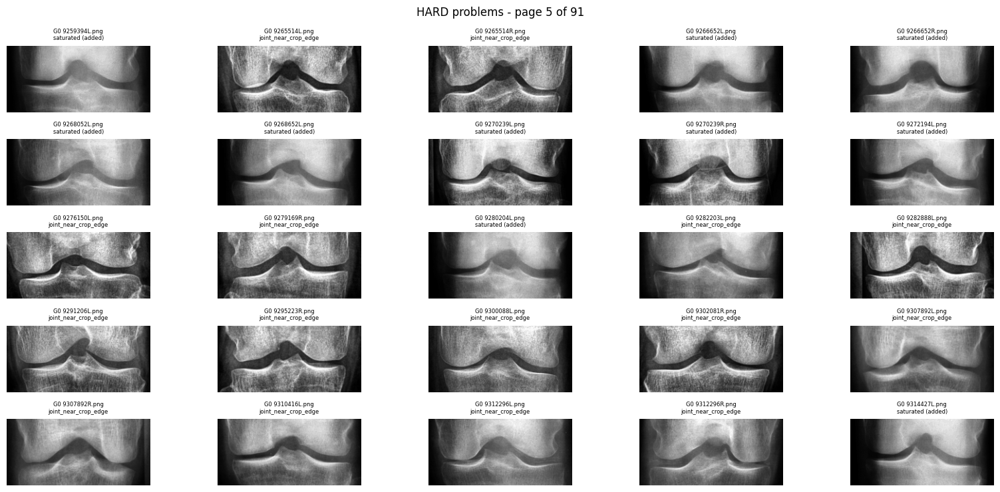

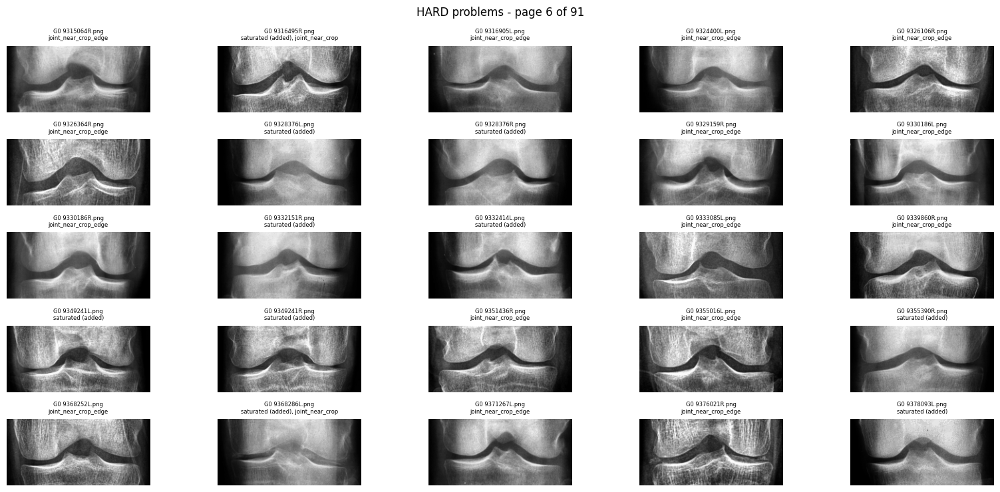

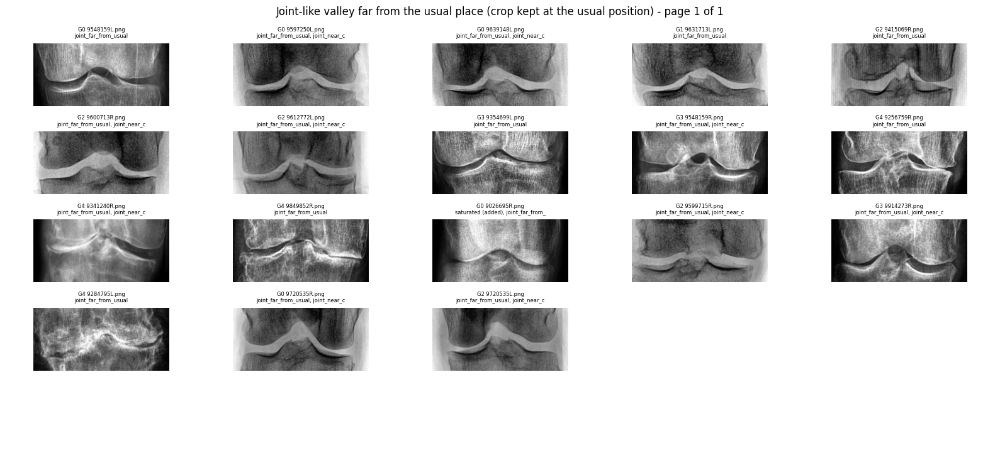

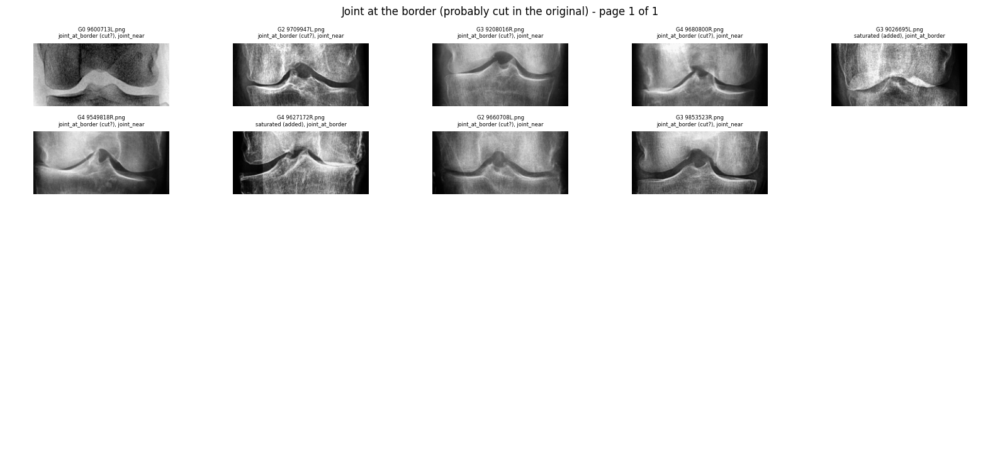

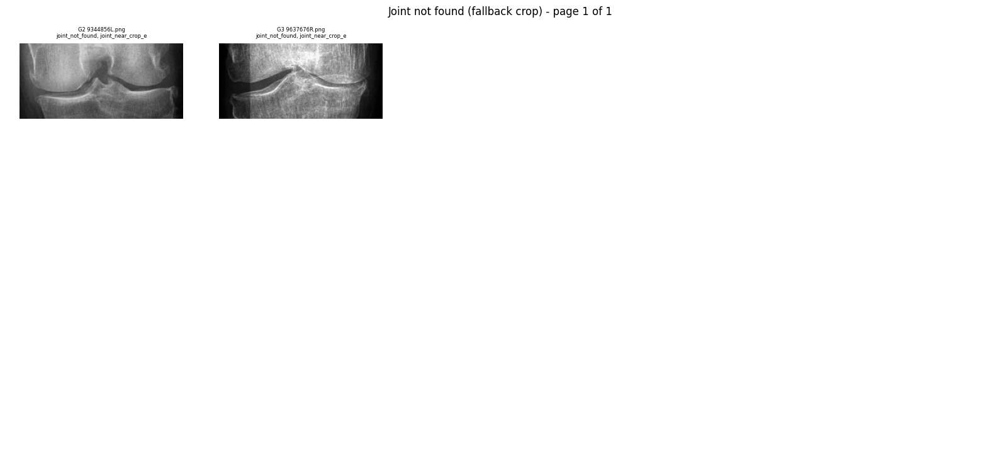

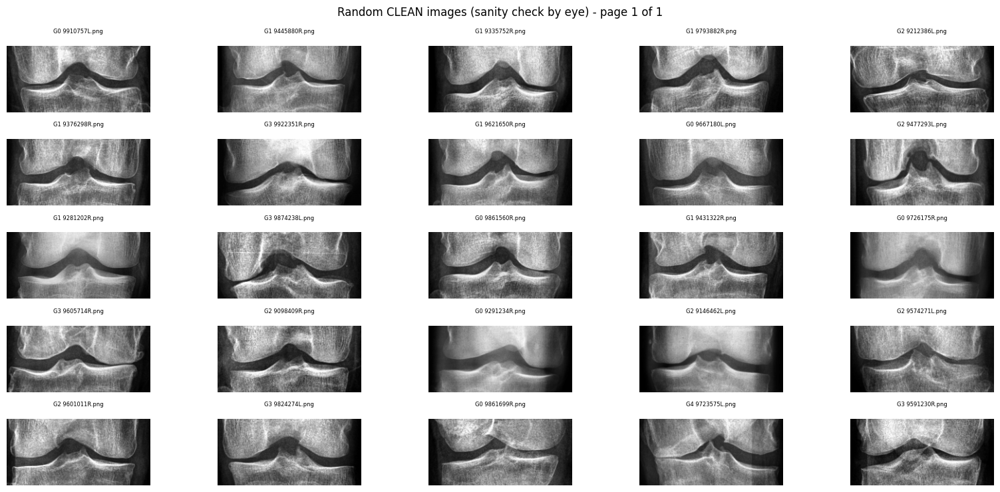


How to read this:
  - HARD must be 0 (or you looked at every image and accepted it).
  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.
  - never remove anything from val/test: the evaluation must stay on the full, untouched set.
  - details per image: standardized_check.csv


In [13]:
# ============ NEW (separate cell): full quality check of the standardized images ============
# Run AFTER the standardization cell (it needs standardize_std, SIZE_STD, WINDOW_H_STD, TARGET_MEAN).
# It measures the image the model will really see (after standardization + crop), for ALL images,
# writes standardized_check.csv and shows every suspicious image with its file name.
import random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- Thresholds (change here only) ----------
MEAN_TOL      = 6      # output mean brightness must be within TARGET_MEAN +/- this
SAT_ADDED_MAX = 0.03   # max EXTRA fraction of pure black/white pixels created by the processing (natural black borders do not count)
RANGE_MIN     = 110    # min (p99 - p1) of the output = enough contrast
RAW_RANGE_MIN = 40     # original with less contrast than this = noise gets amplified
BLACK_MAX     = 0.25   # original with more than this fraction of black pixels (big empty border)
JOINT_PROM    = 8      # min depth of the joint-gap valley in the OUTPUT (brightness levels)
MARGIN_MIN    = 15     # joint must be at least this many pixels away from the top/bottom of the crop
BLUR_PCT      = 2      # sharpness below this percentile of the dataset = suspicious
MAX_PAGES     = 6      # pages shown per category (25 images per page)


def valley_in_crop(crop):
    """Joint gap inside the final crop: (row, depth) of the strongest dark valley, or (None, 0)."""
    H, W = crop.shape
    prof = gaussian_filter1d(crop[:, int(W * .25):int(W * .75)].astype(np.float32).mean(1), sigma=H * 0.03)
    pad = np.pad(prof, 1, constant_values=prof.max() + 1)     # lets a valley sitting AT the crop edge be found too
    pk, pr = find_peaks(-pad, prominence=1)
    if len(pk) == 0:
        return None, 0.0
    i = int(np.argmax(pr["prominences"]))
    return int(pk[i]) - 1, float(pr["prominences"][i])


def check_one(path):
    im = Image.open(path)
    raw = np.array(im.convert("L").resize((SIZE_STD, SIZE_STD)))
    out_img, status = standardize_std(im)                      # exactly what the model gets
    out = np.array(out_img)
    H = out.shape[0]
    p1, p99 = np.percentile(out, (1, 99))
    r1, r99 = np.percentile(raw, (1, 99))
    row, depth = valley_in_crop(out)
    margin = -1 if row is None else min(row, H - row)
    return dict(
        path=path, status=status, orig_size=f"{im.size[0]}x{im.size[1]}",
        raw_mean=raw.mean(), raw_std=raw.std(), raw_range=r99 - r1, raw_black=(raw < 8).mean(),
        raw_sat=((raw == 0) | (raw == 255)).mean(),
        out_mean=out.mean(), out_std=out.std(), out_range=p99 - p1,
        out_sat=((out == 0) | (out == 255)).mean(),
        sharp=cv2.Laplacian(out, cv2.CV_64F).var(),
        joint_row=row, joint_depth=depth, joint_margin=margin, out_h=H,
    )


# ---------- 1) Measure every image ----------
rows = []
for split, ds in [("train", train), ("val", val), ("test", test)]:
    for k, (p, y) in enumerate(ds.samples):
        d = check_one(p); d.update(split=split, grade=y); rows.append(d)
        if (k + 1) % 2000 == 0:
            print(f"  {split}: {k + 1}/{len(ds.samples)}")
df = pd.DataFrame(rows)
sharp_cut = np.percentile(df["sharp"], BLUR_PCT)

# ---------- 2) Flags (one image can have several) ----------
FLAGS = {
    "wrong_size":     (df["out_h"] != WINDOW_H_STD) | (df["orig_size"] != f"{SIZE_STD}x{SIZE_STD}"),
    "brightness_off": (df["out_mean"] - TARGET_MEAN).abs() > MEAN_TOL,
    "saturated (added)": (df["out_sat"] - df["raw_sat"]) > SAT_ADDED_MAX,
    "low_contrast":   df["out_range"] < RANGE_MIN,
    "noisy_original": df["raw_range"] < RAW_RANGE_MIN,
    "blurry":         df["sharp"] < sharp_cut,
    "big_black_area": df["raw_black"] > BLACK_MAX,
    "joint_not_found": df["status"] == "fallback",
    "joint_far_from_usual":   df["status"] == "off_center",
    "joint_at_border (cut?)":    df["status"] == "edge",
    "joint_weak_in_crop": df["joint_depth"] < JOINT_PROM,
    "joint_near_crop_edge": (df["joint_margin"] >= 0) & (df["joint_margin"] < MARGIN_MIN),
}
for k, v in FLAGS.items():
    df[k] = v
HARD = ["wrong_size", "brightness_off", "saturated (added)", "low_contrast", "joint_near_crop_edge"]
SOFT = [k for k in FLAGS if k not in HARD]
df["n_flags"] = df[list(FLAGS)].sum(axis=1)
df["reasons"] = df[list(FLAGS)].apply(lambda r: ", ".join(k for k in FLAGS if r[k]), axis=1)
df.drop(columns=list(FLAGS)).to_csv("standardized_check.csv", index=False)

# ---------- 3) Report ----------
N = len(df)
print(f"\nImages checked: {N}  (train {sum(df.split == 'train')} | val {sum(df.split == 'val')} | test {sum(df.split == 'test')})")
print(f"\n{'check':32s}{'images':>8s}{'%':>7s}")
for k in HARD + SOFT:
    n = int(df[k].sum()); print(f"{('[HARD] ' if k in HARD else '[soft] ') + k:32s}{n:8d}{100 * n / N:6.1f}%")
clean = int((df["n_flags"] == 0).sum())
print(f"{'clean (no flag at all)':32s}{clean:8d}{100 * clean / N:6.1f}%")

print("\nBrightness uniformity (std of mean brightness across images; smaller = more uniform):")
print(f"  before standardization: {df.raw_mean.std():.1f}   after: {df.out_mean.std():.1f}")
print(f"Contrast (std of pixel values): spread across images before {df.raw_std.std():.1f} | after {df.out_std.std():.1f}")
print(f"Pure black/white pixels: original {100 * df.raw_sat.mean():.1f}% of all pixels | after processing {100 * df.out_sat.mean():.1f}%")
print("\nMean brightness per grade (should be almost equal after; a gap would let the model cheat on brightness):")
print(df.groupby("grade")[["raw_mean", "out_mean"]].mean().round(1).to_string())
print("\nMean brightness per split (train / val / test must look the same):")
print(df.groupby("split")[["out_mean", "out_std", "sharp"]].mean().round(1).to_string())
print("\nJoint position inside the crop (rows 0-%d, centre = %d):" % (WINDOW_H_STD, WINDOW_H_STD // 2))
j = df[df.joint_row.notna()]
print(f"  median {j.joint_row.median():.0f} | 5th-95th percentile {j.joint_row.quantile(.05):.0f}-{j.joint_row.quantile(.95):.0f}")

# ---------- 4) Look at the suspicious images (file names in the titles) ----------
def show(items, title, max_pages=MAX_PAGES):
    items = list(items)
    for pg in range(min(max_pages, -(-len(items) // 25))):
        fig, axes = plt.subplots(5, 5, figsize=(16, 7.5))
        for ax in axes.ravel(): ax.axis("off")
        for ax, (_, r) in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
            ax.imshow(standardize_std(Image.open(r.path))[0], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"G{r.grade} {r.path.split('/')[-1][:18]}\n{r.reasons[:34]}", fontsize=6)
        fig.suptitle(f"{title} - page {pg + 1} of {-(-len(items) // 25)}")
        plt.tight_layout(); plt.show()

hard_any = df[df[HARD].any(axis=1)]
print(f"\nImages with at least one HARD problem: {len(hard_any)}")
if len(hard_any): show(hard_any.iterrows(), "HARD problems")
far = df[df["joint_far_from_usual"]]
if len(far): show(far.iterrows(), "Joint-like valley far from the usual place (crop kept at the usual position)")
cut = df[df["joint_at_border (cut?)"]]
if len(cut): show(cut.iterrows(), "Joint at the border (probably cut in the original)")
weak = df[df["joint_weak_in_crop"] & ~df["joint_at_border (cut?)"] & ~df["joint_far_from_usual"] & ~df["joint_not_found"]]
if len(weak): show(weak.iterrows(), "Joint gap weak/invisible inside the crop", 3)
nf = df[df["joint_not_found"]]
if len(nf): show(nf.iterrows(), "Joint not found (fallback crop)", 2)
random.seed(0)
show(df[df.n_flags == 0].sample(25, random_state=0).iterrows(), "Random CLEAN images (sanity check by eye)", 1)

print("\nHow to read this:")
print("  - HARD must be 0 (or you looked at every image and accepted it).")
print("  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.")
print("  - never remove anything from val/test: the evaluation must stay on the full, untouched set.")
print("  - details per image: standardized_check.csv")


  train: 2000/5778
  train: 4000/5778

Images checked: 8260  (train 5778 | val 826 | test 1656)

check                             images      %
[HARD] wrong_size                      0   0.0%
[HARD] brightness_off                  0   0.0%
[HARD] low_contrast                    0   0.0%
[HARD] joint_near_crop_edge            7   0.1%
[soft] saturated (added)             439   5.3%
[soft] noisy_original                 14   0.2%
[soft] blurry                        166   2.0%
[soft] big_black_area                  0   0.0%
[soft] joint_not_found                 2   0.0%
[soft] joint_far_from_usual           18   0.2%
[soft] joint_at_border (cut?)          9   0.1%
[soft] joint_weak_in_crop              6   0.1%
clean (no flag at all)              7616  92.2%

Brightness uniformity (std of mean brightness across images; smaller = more uniform):
  before standardization: 27.3   after: 0.1
Contrast (std of pixel values): spread across images before 14.4 | after 5.0
Pure black/white pixels

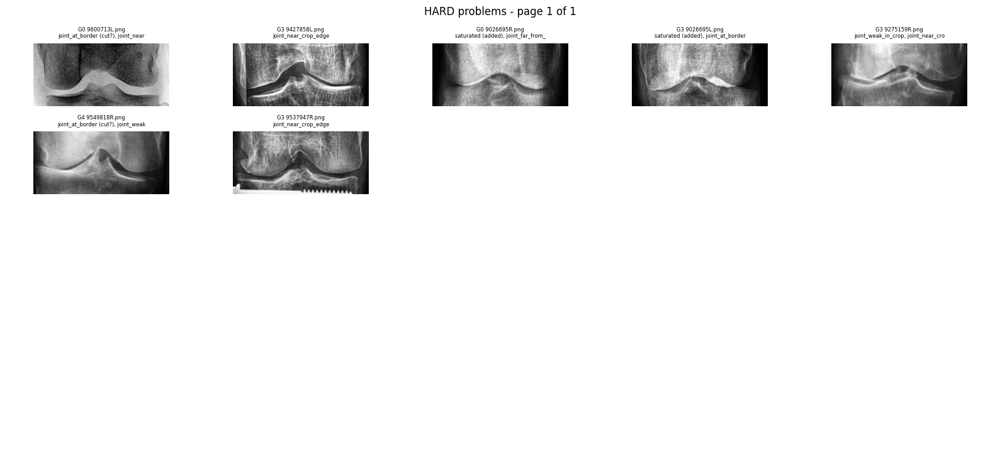

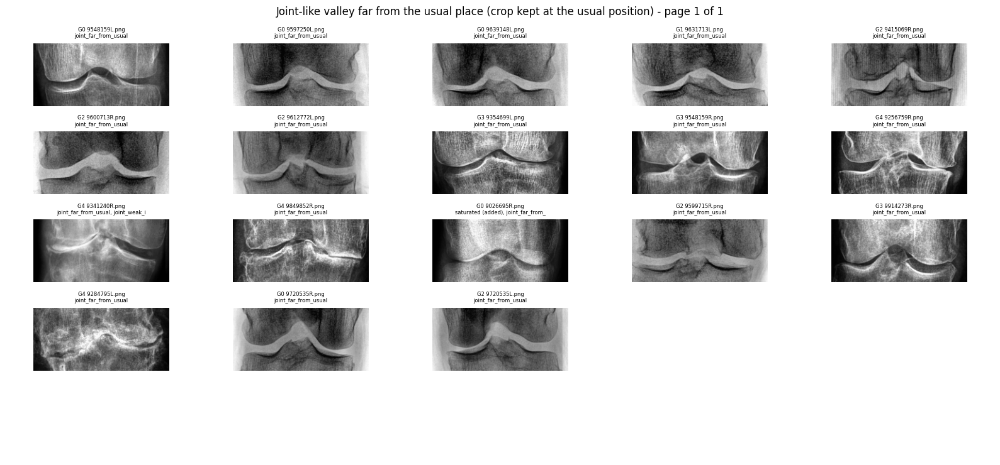

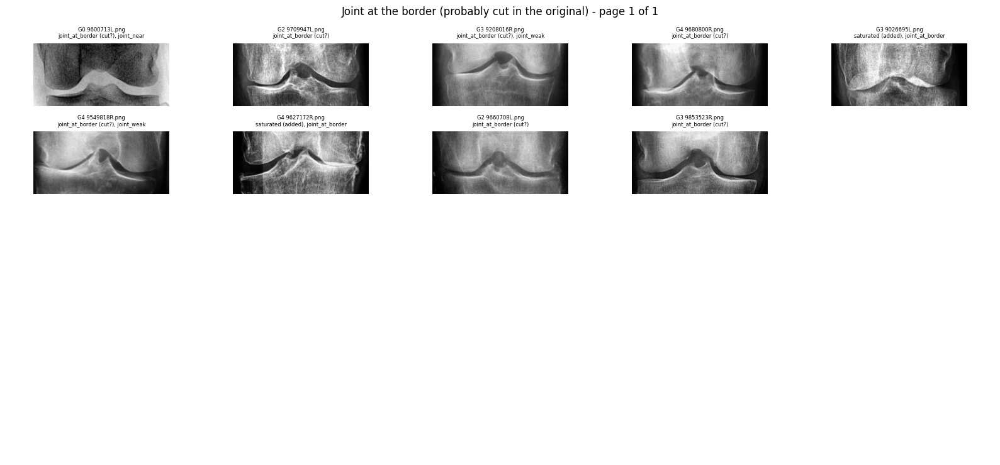

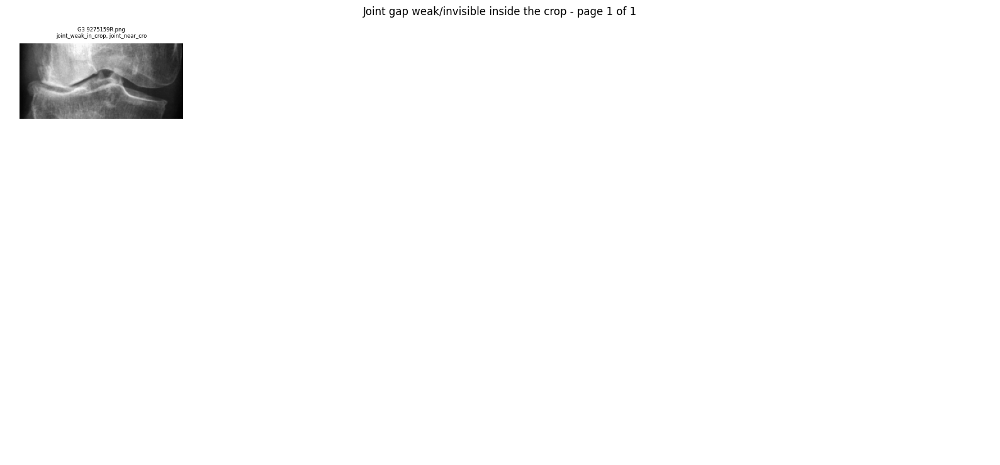

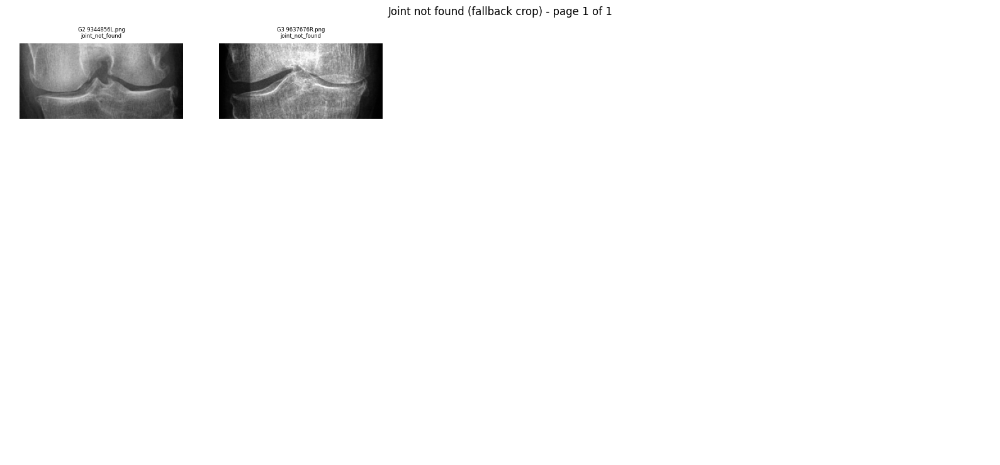

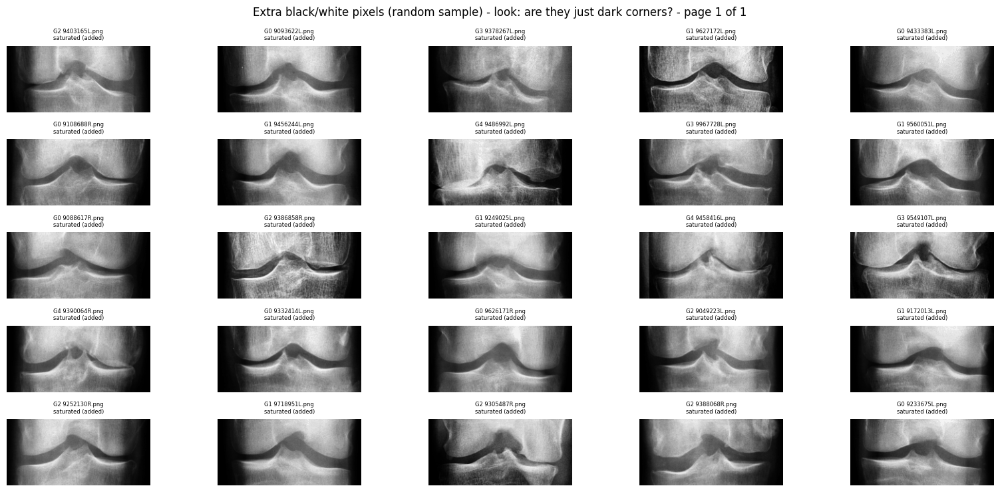

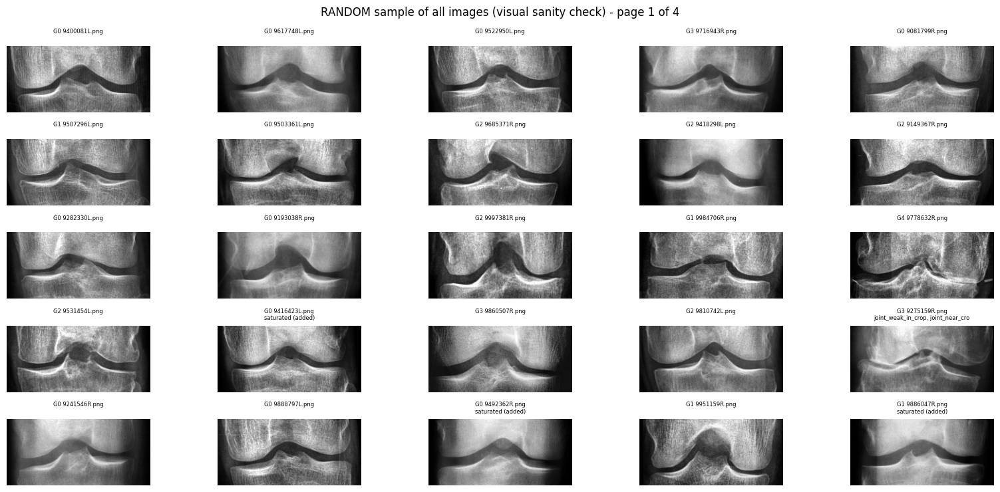

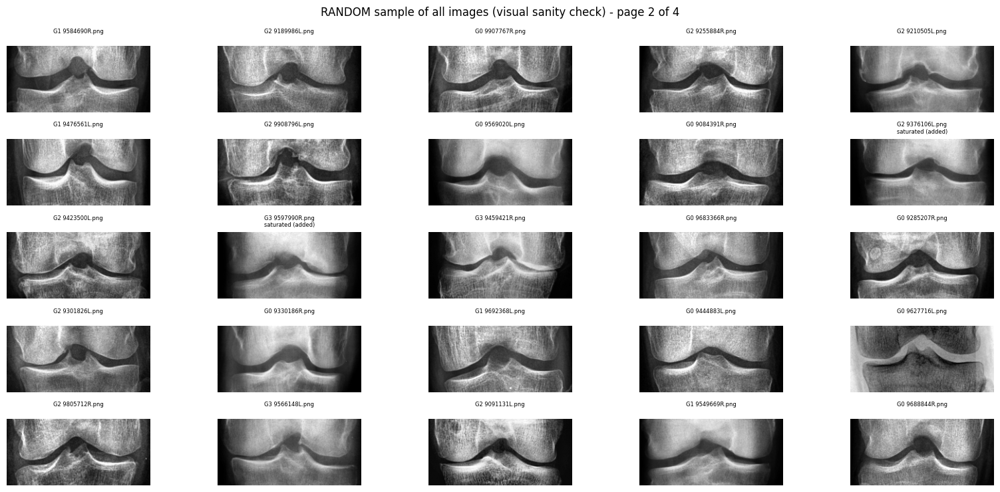

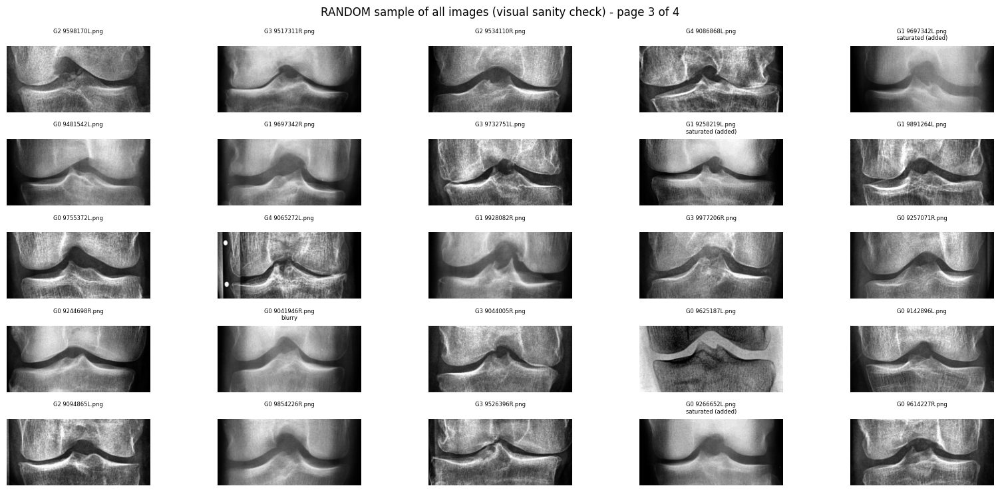

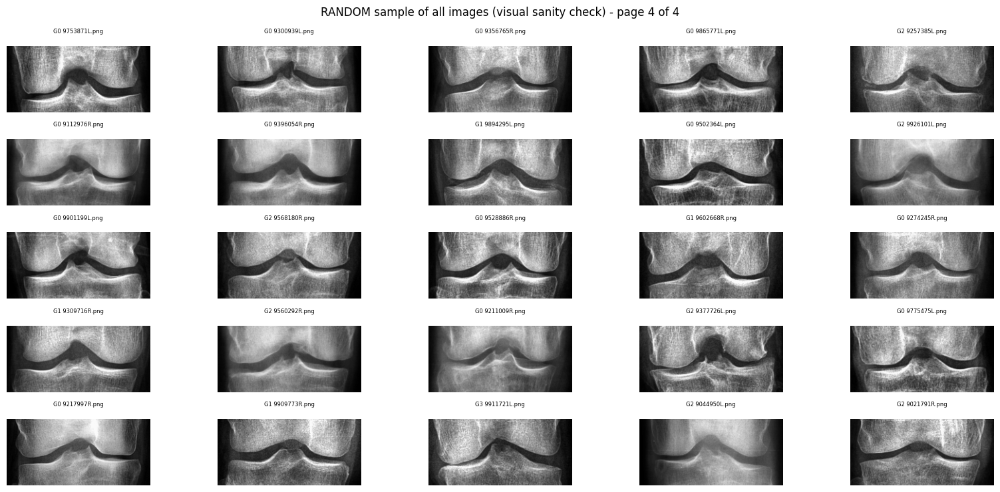


How to read this:
  - HARD must be 0 (or you looked at every image and accepted it).
  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.
  - never remove anything from val/test: the evaluation must stay on the full, untouched set.
  - details per image: standardized_check.csv


In [15]:
# ============ NEW (separate cell): full quality check of the standardized images ============
# Run AFTER the standardization cell (it needs standardize_std, SIZE_STD, WINDOW_H_STD, TARGET_MEAN).
# It measures the image the model will really see (after standardization + crop), for ALL images,
# writes standardized_check.csv and shows every suspicious image with its file name.
import random
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt
from PIL import Image
from scipy.ndimage import gaussian_filter1d
from scipy.signal import find_peaks

# ---------- Thresholds (change here only) ----------
MEAN_TOL      = 6      # output mean brightness must be within TARGET_MEAN +/- this
SAT_ADDED_MAX = 0.03   # max EXTRA fraction of pure black/white pixels created by the processing (natural black borders do not count)
RANGE_MIN     = 110    # min (p99 - p1) of the output = enough contrast
RAW_RANGE_MIN = 40     # original with less contrast than this = noise gets amplified
BLACK_MAX     = 0.25   # original with more than this fraction of black pixels (big empty border)
JOINT_PROM    = 8      # min depth of the joint-gap valley in the OUTPUT (brightness levels)
MARGIN_MIN    = 15     # joint must be at least this many pixels away from the top/bottom of the crop
BLUR_PCT      = 2      # sharpness below this percentile of the dataset = suspicious
MAX_PAGES     = 6      # pages shown per category (25 images per page)


def valley_in_crop(crop):
    """Joint gap inside the final crop: (row, depth) of the strongest dark valley, or (None, 0)."""
    H, W = crop.shape
    prof = gaussian_filter1d(crop[:, int(W * .25):int(W * .75)].astype(np.float32).mean(1), sigma=H * 0.03)
    pk, pr = find_peaks(-prof, prominence=1)                  # interior valleys only (an edge "valley" is not evidence of a joint)
    if len(pk) == 0:
        return None, 0.0
    i = int(np.argmax(pr["prominences"]))
    return int(pk[i]), float(pr["prominences"][i])


def check_one(path):
    im = Image.open(path)
    raw = np.array(im.convert("L").resize((SIZE_STD, SIZE_STD)))
    out_img, status = standardize_std(im)                      # exactly what the model gets
    out = np.array(out_img)
    H = out.shape[0]
    p1, p99 = np.percentile(out, (1, 99))
    r1, r99 = np.percentile(raw, (1, 99))
    row, depth = valley_in_crop(out)
    margin = -1 if row is None else min(row, H - row)
    return dict(
        path=path, status=status, orig_size=f"{im.size[0]}x{im.size[1]}",
        raw_mean=raw.mean(), raw_std=raw.std(), raw_range=r99 - r1, raw_black=(raw < 8).mean(),
        raw_sat=((raw == 0) | (raw == 255)).mean(),
        out_mean=out.mean(), out_std=out.std(), out_range=p99 - p1,
        out_sat=((out == 0) | (out == 255)).mean(),
        sharp=cv2.Laplacian(out, cv2.CV_64F).var(),
        joint_row=row, joint_depth=depth, joint_margin=margin, out_h=H,
    )


# ---------- 1) Measure every image ----------
rows = []
for split, ds in [("train", train), ("val", val), ("test", test)]:
    for k, (p, y) in enumerate(ds.samples):
        d = check_one(p); d.update(split=split, grade=y); rows.append(d)
        if (k + 1) % 2000 == 0:
            print(f"  {split}: {k + 1}/{len(ds.samples)}")
df = pd.DataFrame(rows)
sharp_cut = np.percentile(df["sharp"], BLUR_PCT)

# ---------- 2) Flags (one image can have several) ----------
FLAGS = {
    "wrong_size":     (df["out_h"] != WINDOW_H_STD) | (df["orig_size"] != f"{SIZE_STD}x{SIZE_STD}"),
    "brightness_off": (df["out_mean"] - TARGET_MEAN).abs() > MEAN_TOL,
    "saturated (added)": (df["out_sat"] - df["raw_sat"]) > SAT_ADDED_MAX,
    "low_contrast":   df["out_range"] < RANGE_MIN,
    "noisy_original": df["raw_range"] < RAW_RANGE_MIN,
    "blurry":         df["sharp"] < sharp_cut,
    "big_black_area": df["raw_black"] > BLACK_MAX,
    "joint_not_found": df["status"] == "fallback",
    "joint_far_from_usual":   df["status"] == "off_center",
    "joint_at_border (cut?)":    df["status"] == "edge",
    "joint_weak_in_crop": df["joint_depth"] < JOINT_PROM,
    "joint_near_crop_edge": (df["joint_margin"] >= 0) & (df["joint_margin"] < MARGIN_MIN),
}
for k, v in FLAGS.items():
    df[k] = v
HARD = ["wrong_size", "brightness_off", "low_contrast", "joint_near_crop_edge"]   # "saturated (added)" is soft: CLAHE + the 1% stretch create some white/black pixels by design
SOFT = [k for k in FLAGS if k not in HARD]
df["n_flags"] = df[list(FLAGS)].sum(axis=1)
df["reasons"] = df[list(FLAGS)].apply(lambda r: ", ".join(k for k in FLAGS if r[k]), axis=1)
df.drop(columns=list(FLAGS)).to_csv("standardized_check.csv", index=False)

# ---------- 3) Report ----------
N = len(df)
print(f"\nImages checked: {N}  (train {sum(df.split == 'train')} | val {sum(df.split == 'val')} | test {sum(df.split == 'test')})")
print(f"\n{'check':32s}{'images':>8s}{'%':>7s}")
for k in HARD + SOFT:
    n = int(df[k].sum()); print(f"{('[HARD] ' if k in HARD else '[soft] ') + k:32s}{n:8d}{100 * n / N:6.1f}%")
clean = int((df["n_flags"] == 0).sum())
print(f"{'clean (no flag at all)':32s}{clean:8d}{100 * clean / N:6.1f}%")

print("\nBrightness uniformity (std of mean brightness across images; smaller = more uniform):")
print(f"  before standardization: {df.raw_mean.std():.1f}   after: {df.out_mean.std():.1f}")
print(f"Contrast (std of pixel values): spread across images before {df.raw_std.std():.1f} | after {df.out_std.std():.1f}")
print(f"Pure black/white pixels: original {100 * df.raw_sat.mean():.1f}% of all pixels | after processing {100 * df.out_sat.mean():.1f}%")
print("\nMean brightness per grade (should be almost equal after; a gap would let the model cheat on brightness):")
print(df.groupby("grade")[["raw_mean", "out_mean"]].mean().round(1).to_string())
print("\nMean brightness per split (train / val / test must look the same):")
print(df.groupby("split")[["out_mean", "out_std", "sharp"]].mean().round(1).to_string())
print("\nJoint position inside the crop (rows 0-%d, centre = %d):" % (WINDOW_H_STD, WINDOW_H_STD // 2))
j = df[df.joint_row.notna()]
print(f"  median {j.joint_row.median():.0f} | 5th-95th percentile {j.joint_row.quantile(.05):.0f}-{j.joint_row.quantile(.95):.0f}")

# ---------- 4) Look at the suspicious images (file names in the titles) ----------
def show(items, title, max_pages=MAX_PAGES):
    items = list(items)
    for pg in range(min(max_pages, -(-len(items) // 25))):
        fig, axes = plt.subplots(5, 5, figsize=(16, 7.5))
        for ax in axes.ravel(): ax.axis("off")
        for ax, (_, r) in zip(axes.ravel(), items[pg * 25:(pg + 1) * 25]):
            ax.imshow(standardize_std(Image.open(r.path))[0], cmap="gray", vmin=0, vmax=255)
            ax.set_title(f"G{r.grade} {r.path.split('/')[-1][:18]}\n{r.reasons[:34]}", fontsize=6)
        fig.suptitle(f"{title} - page {pg + 1} of {-(-len(items) // 25)}")
        plt.tight_layout(); plt.show()

hard_any = df[df[HARD].any(axis=1)]
print(f"\nImages with at least one HARD problem: {len(hard_any)}")
if len(hard_any): show(hard_any.iterrows(), "HARD problems")
far = df[df["joint_far_from_usual"]]
if len(far): show(far.iterrows(), "Joint-like valley far from the usual place (crop kept at the usual position)")
cut = df[df["joint_at_border (cut?)"]]
if len(cut): show(cut.iterrows(), "Joint at the border (probably cut in the original)")
weak = df[df["joint_weak_in_crop"] & ~df["joint_at_border (cut?)"] & ~df["joint_far_from_usual"] & ~df["joint_not_found"]]
if len(weak): show(weak.iterrows(), "Joint gap weak/invisible inside the crop", 3)
nf = df[df["joint_not_found"]]
if len(nf): show(nf.iterrows(), "Joint not found (fallback crop)", 2)
random.seed(0)
sat_added = df[df["saturated (added)"]]
if len(sat_added): show(sat_added.sample(min(25, len(sat_added)), random_state=0).iterrows(), "Extra black/white pixels (random sample) - look: are they just dark corners?", 1)
# 100 random images of ALL images (not only the "clean" ones): if you look at them all and see no problem,
# the share of bad images is below about 3% (95% confidence, "rule of three")
show(df.sample(min(100, len(df)), random_state=1).iterrows(), "RANDOM sample of all images (visual sanity check)", 4)

print("\nHow to read this:")
print("  - HARD must be 0 (or you looked at every image and accepted it).")
print("  - soft flags are 'please look', not necessarily wrong. Train images you confirm are bad can be removed from TRAIN only.")
print("  - never remove anything from val/test: the evaluation must stay on the full, untouched set.")
print("  - details per image: standardized_check.csv")
